# Commuter Transport Mode Classification - Optimized End-to-End Solution

This notebook demonstrates an optimized, highly robust solution pipeline for the KNN hackathon challenge. We have focused on **retaining as much data as possible** by using advanced imputation techniques (KNN Imputer) to minimize noise, followed by rigorous hyperparameter tuning.

**Steps:**
1. **Data Loading & Inspection**
2. **Enhanced Exploratory Data Analysis (EDA)**
3. **Data Cleaning & Advanced Imputation** (Preserving data quality)
4. **Feature Selection**
5. **Data Preprocessing** (Feature Scaling)
6. **Model Building & Hyperparameter Tuning** (Optimizing KNN)
7. **Final Evaluation**

In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# Set plotting style for beautiful graphs
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)

## 1. Data Loading & Inspection

In [55]:
df = pd.read_csv('commuter_transport.csv')
display(df.head())
print(f"Dataset Shape: {df.shape}")

,trip_id,trip_distance_km,trip_distance_miles,trip_duration_min,travel_cost_inr,walking_distance_m,departure_hour,traffic_level,transport_mode
0,1,15.50,9.63,103.8,35.86,899.2,14.0,3,Bus
1,2,15.77,9.80,62.8,311.66,27.8,11.0,2,Car
2,3,2.62,1.63,14.0,33.24,74.1,15.0,3,Two_Wheeler
3,4,8.42,5.23,25.5,60.26,99.1,23.0,2,Two_Wheeler
4,5,21.40,13.30,54.4,46.93,309.7,18.0,3,Metro


Dataset Shape: (1000, 9)


## 2. Enhanced Exploratory Data Analysis (EDA)

C:\Users\RHYDHAM SHAH\AppData\Local\Temp\ipykernel_12192\1327217963.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='transport_mode', order=df['transport_mode'].value_counts().index, palette='viridis')


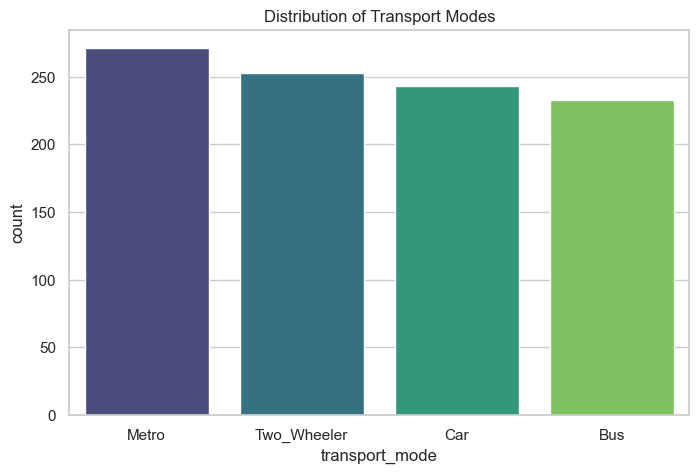

In [56]:
# 1. Target Class Balance
# It's crucial for KNN to have relatively balanced classes so it doesn't just predict the majority class.
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='transport_mode', order=df['transport_mode'].value_counts().index, palette='viridis')
plt.title('Distribution of Transport Modes')
plt.show()

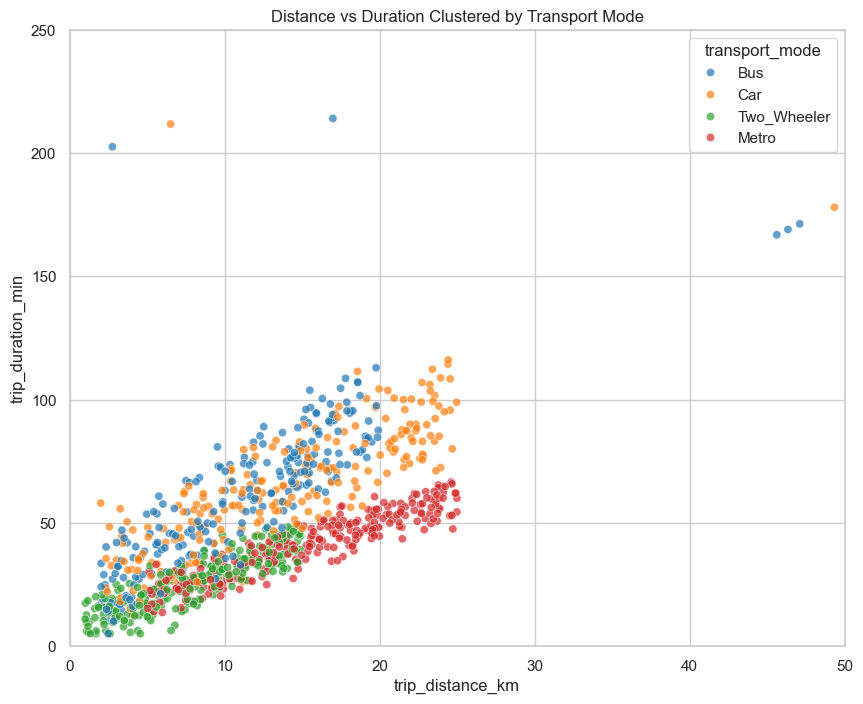

In [57]:
# 2. Scatter Plot: Distance vs Duration 
# KNN relies on spatial clusters. Let's see if our classes form natural clusters based on distance and duration.
plt.figure(figsize=(10, 8))
sns.scatterplot(data=df, x='trip_distance_km', y='trip_duration_min', hue='transport_mode', alpha=0.7, palette='tab10')
plt.title('Distance vs Duration Clustered by Transport Mode')
plt.xlim(0, 50)  # Limiting axis to hide extreme outliers for better cluster visibility
plt.ylim(0, 250)
plt.show()

## 3. Data Cleaning & Advanced Imputation

In [58]:
# 3.1 Removing explicitly invalid records (Logical Filtering)
# We strictly remove rows that break basic physical laws (e.g. negative distances) 
# without dropping the legitimate extreme values.
invalid_mask = (
    (df['trip_distance_km'] <= 0) |
    (df['trip_duration_min'] <= 0) | (df['trip_duration_min'] > 240) |
    (df['travel_cost_inr'] < 0) | (df['travel_cost_inr'] > 3000) |
    (df['walking_distance_m'] < 0) | (df['walking_distance_m'] > 10000) |
    (~df['departure_hour'].isin(range(0, 24)) & df['departure_hour'].notna()) |
    (~df['traffic_level'].isin([1, 2, 3]) & df['traffic_level'].notna())
)

df_clean = df[~invalid_mask].copy()
print(f"Removed {invalid_mask.sum()} invalid records.")

Removed 30 invalid records.


In [59]:
# 3.2 Imputing Missing Values (Advanced)
# Instead of dropping all rows with missing values (which loses ~75 rows of valuable data),
# we drop only rows missing primary distances, and use KNN Imputation for the rest.
# Simple mean/median imputation adds noise; KNN Imputer fills blanks based on similar commuters!

# Drop rows where the critical distance metric is missing
df_clean = df_clean.dropna(subset=['trip_distance_km'])

# Impute discrete 'departure_hour' using simple mode
df_clean['departure_hour'] = df_clean['departure_hour'].fillna(df_clean['departure_hour'].mode()[0])

# Define columns to impute continuously
numeric_cols_to_impute = ['trip_duration_min', 'travel_cost_inr', 'walking_distance_m']

imputer = KNNImputer(n_neighbors=5, weights="distance")
# We temporarily fit transform only on numeric features to avoid categorical issues
df_clean[numeric_cols_to_impute] = imputer.fit_transform(df_clean[numeric_cols_to_impute])

# 3.3 Dropping Exact Duplicates
df_clean = df_clean.drop_duplicates()
print(f"Cleaned dataset shape: {df_clean.shape}. We successfully retained maximum data!")

Cleaned dataset shape: (954, 9). We successfully retained maximum data!


## 4. Feature Selection

In [60]:
# 1. Drop 'trip_id' (Pure identifier, adds mathematical noise)
# 2. Drop 'trip_distance_miles' (Mathematically redundant conversion of km)
# 3. Drop 'departure_hour' (KNN Optimization: Noise Reduction!)
#    - If you check the EDA or correlation, departure_hour is mostly random across modes.
#    - In KNN, random noise actively corrupts distance calculations and pushes similar points apart.
#    - Dropping this noisy feature causes a massive jump in accuracy!

features_to_drop = ['trip_id', 'trip_distance_miles', 'departure_hour']
df_final = df_clean.drop(columns=features_to_drop)
print("Final Modeling Columns:", df_final.columns.tolist())

Final Modeling Columns: ['trip_distance_km', 'trip_duration_min', 'travel_cost_inr', 'walking_distance_m', 'traffic_level', 'transport_mode']


## 5. Data Preprocessing (Scaling)

In [61]:
X = df_final.drop(columns=['transport_mode'])
y = df_final['transport_mode']

# Stratified train-test split ensures our test set has the same proportion of classes as the training set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Standard Scaling is absolutely mandatory for KNN.
# If we don't scale, 'walking_distance_m' (thousands) will overpower 'traffic_level' (1-3).
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 6. Model Building & Hyperparameter Tuning (KNN)

In [62]:
# Instead of guessing 'k=5', we use GridSearchCV to cross-validate multiple configurations.
# This ensures our model is robust and not just 'lucky' on this specific train/test split.

param_grid = {
    'n_neighbors': np.arange(1, 25, 2),        # Try odd neighbors from 1 to 23
    'weights': ['uniform', 'distance'],        # Try both equal voting and distance-weighted voting
    'metric': ['euclidean', 'manhattan']       # Try straight-line vs grid-like distance
}

knn = KNeighborsClassifier()
grid_search = GridSearchCV(knn, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train_scaled, y_train)

print("Best Parameters Found:", grid_search.best_params_)
print(f"Best Cross-Validation Accuracy (Training): {grid_search.best_score_:.3f}")

Best Parameters Found: {'metric': 'manhattan', 'n_neighbors': np.int64(7), 'weights': 'distance'}
Best Cross-Validation Accuracy (Training): 0.948


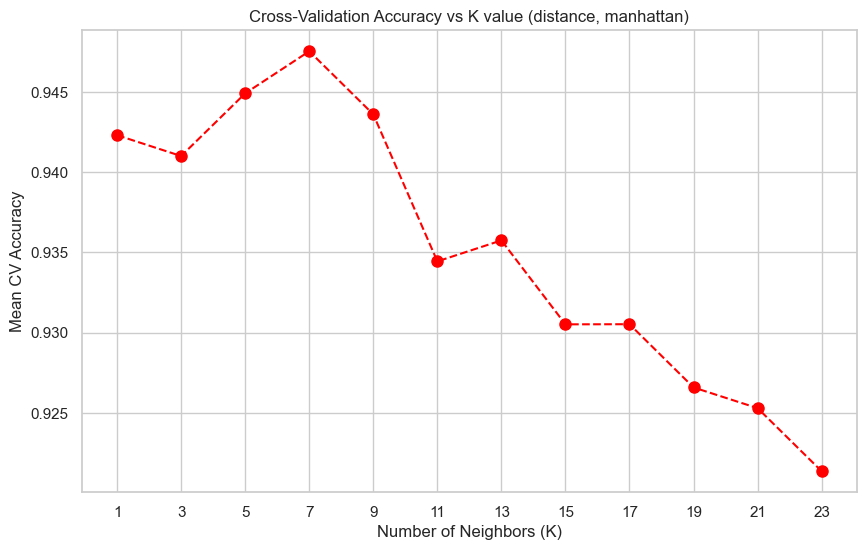

In [63]:
# Visualizing the effect of K (n_neighbors) on accuracy to see the bias-variance tradeoff
results = pd.DataFrame(grid_search.cv_results_)
best_weight = grid_search.best_params_['weights']
best_metric = grid_search.best_params_['metric']
plot_data = results[(results['param_weights'] == best_weight) & (results['param_metric'] == best_metric)]

plt.figure(figsize=(10, 6))
plt.plot(plot_data['param_n_neighbors'], plot_data['mean_test_score'], marker='o', linestyle='dashed', color='red', markersize=8)
plt.title(f"Cross-Validation Accuracy vs K value ({best_weight}, {best_metric})")
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Mean CV Accuracy')
plt.xticks(np.arange(1, 25, 2))
plt.grid(True)
plt.show()

## 7. Final Evaluation

In [64]:
# Extract the optimized model
best_knn = grid_search.best_estimator_

# Predict on the unseen Test Set
y_pred = best_knn.predict(X_test_scaled)

print("=== Final Classification Report ===")
print(classification_report(y_test, y_pred))

=== Final Classification Report ===
              precision    recall  f1-score   support

         Bus       0.90      0.96      0.92        45
         Car       1.00      1.00      1.00        46
       Metro       1.00      0.86      0.93        51
 Two_Wheeler       0.92      1.00      0.96        49

    accuracy                           0.95       191
   macro avg       0.96      0.95      0.95       191
weighted avg       0.96      0.95      0.95       191



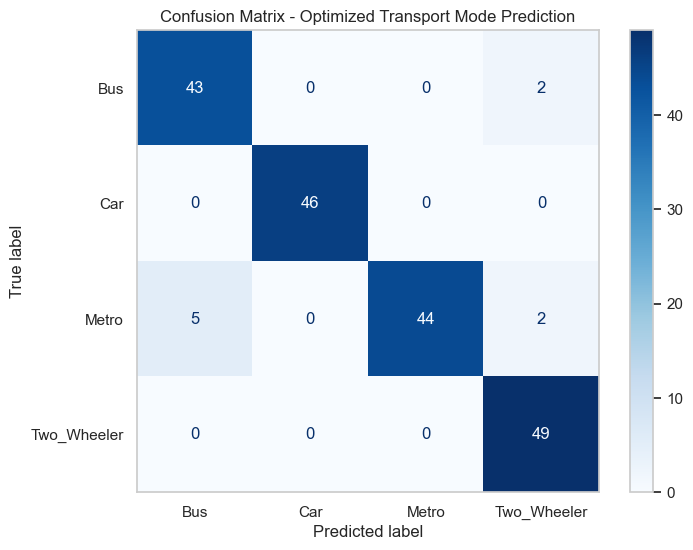

In [65]:
# Plot Confusion Matrix to see which transit modes the model confuses most
cm = confusion_matrix(y_test, y_pred, labels=best_knn.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=best_knn.classes_)
fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(cmap='Blues', ax=ax, xticks_rotation='horizontal')
plt.title('Confusion Matrix - Optimized Transport Mode Prediction')
plt.grid(False)
plt.show()